<h1 style="text-align:center; color:red;">Assignment: Titanic &amp; Tips</h1>
<h3 style="text-align:center; color:green;">Instructor: Dr. Khaled Mohamad</h3>

**Instructions:** Answer all questions in order. Write clean, well commented code and use consistent Markdown formatting.

---

**Dataset Overview** You will continue working with the **Titanic** dataset and the **Tips** dataset (both built into Seaborn). No file uploads are needed.

In [278]:
# import necessry lib.
import seaborn as sns

---
<h2 style="text-align:center; color:blue;">Part 1: Data Loading &amp; Exploration</h2>

---

## Q1. Load, Inspect

1. Load the Titanic dataset into `df` and the Tips dataset into `tips`.
2. For the Titanic dataset, print:
    - Shape, column names, and dtypes.
    - The percentage of missing values per column (not just the count), rounded to 1 decimal place, sorted descending.
3. Using a single line of pandas code, display only the columns that contain at least one missing value.
4. In a Markdown cell, explain why dropping the `deck` column is more appropriate than imputing it.

In [279]:
# 1) Load datasets
df = sns.load_dataset("titanic")
tips = sns.load_dataset("tips")

In [280]:
# 2) Shape, columns, dtypes
print(f"Titanic dataset characteristics:\nShape: {df.shape},\nColumns: {df.columns},\nDtypes: \n{df.dtypes}")


Titanic dataset characteristics:
Shape: (891, 15),
Columns: Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='str'),
Dtypes: 
survived          int64
pclass            int64
sex                 str
age             float64
sibsp             int64
parch             int64
fare            float64
embarked            str
class          category
who                 str
adult_male         bool
deck           category
embark_town         str
alive               str
alone              bool
dtype: object


In [281]:
# Percentage missing, sorted descending
print(((df.isnull().mean()*100).round(1)).sort_values(ascending=False))

deck           77.2
age            19.9
embarked        0.2
embark_town     0.2
survived        0.0
pclass          0.0
sex             0.0
sibsp           0.0
parch           0.0
fare            0.0
class           0.0
who             0.0
adult_male      0.0
alive           0.0
alone           0.0
dtype: float64


In [282]:
# 3) Columns with at least one missing value — single line
df.loc[:, df.isnull().any()]

,age,embarked,deck,embark_town
0,22.0,S,NaN,Southampton
1,38.0,C,C,Cherbourg
2,26.0,S,NaN,Southampton
3,35.0,S,C,Southampton
4,35.0,S,NaN,Southampton
...,...,...,...,...
886,27.0,S,NaN,Southampton
887,19.0,S,B,Southampton
888,NaN,S,NaN,Southampton
889,26.0,C,C,Cherbourg


### Answer Q1.4

Because `deck` column is missing about 77.2 percent, so there is only small amount of real data remains. Filling with the mode would make the column almost constant.

---

## Q2. Missing Treatments

Create `df_clean` from `df` and apply the following in order:

1. Drop `deck`, `alive`, and `embark_town` (redundant or mostly missing).
2. Fill `age` missing values using the median age grouped by `pclass` and `sex`. Use `transform` function.
3. Fill `embarked` with its mode.
4. Remove duplicate rows.
5. Print the shape before and after, and confirm zero missing values remain.

> **Hint for step 2:** `df_clean['age'] = df_clean.groupby(['pclass','sex'])['age'].transform(lambda x: x.fillna(x.median()))`

In [283]:
# 1) Drop redundant &  high-missing columns
df_clean = df.drop(columns=['deck', 'alive', 'embark_town'])

In [284]:
# 2) Group-based median imputation for age
df_clean['age'] = df_clean.groupby(['pclass','sex'])['age'].transform(lambda x: x.fillna(x.median()))

In [285]:
# 3) Fill embarked with mode
df_clean['embarked'] = df_clean['embarked'].fillna(df_clean['embarked'].mode()[0])

In [286]:
# 4)Remove duplicates
df_clean = df_clean.drop_duplicates()

print(f"Shape before: {df.shape}\nShape after: {df_clean.shape}\nMissing values remaining: {df_clean.isnull().sum().sum()}")

Shape before: (891, 15)
Shape after: (773, 12)
Missing values remaining: 0


---
<h2 style="text-align:center; color:blue;">Part 2: Feature Engineering</h2>

---

## Q3. Create Meaningful Features

Using `df_clean`, engineer the following new columns:

1. `family_size` = `sibsp + parch + 1` (passenger counts as 1).
2. `is_alone` = 1 if `family_size == 1`, else 0 (integer, not boolean).
3. `age_group` = a categorical column based on age bins:
    - `Child` (0–12), `Teen` (12–18), `Adult` (18–60), `Senior` (60+).
      Use `pd.cut` with `labels=['Child','Teen','Adult','Senior']`.
4. `fare_per_person` = `fare / family_size` (round to 2 decimal places).
5. Print the value counts of `age_group` and the first 5 rows of the new columns.

In [287]:
# 1) Family size
df_clean['family_size'] = df_clean['sibsp'] + df_clean['parch'] + 1

In [288]:
# 2) Is alone
df_clean['is_alone'] = (df_clean['family_size'] == 1).astype(int)

In [289]:
# 3) Age group
import pandas as pd

df_clean['age_group'] = pd.cut(df_clean['age'], bins=[0, 12, 18, 60, float('inf')], labels=['Child','Teen','Adult','Senior'])

In [290]:
# 4) Fare per person
df_clean['fare_per_person'] = (df_clean['fare'] / df_clean['family_size']).round(2)

In [291]:
# 5) Summary
print(df_clean['age_group'].value_counts())
print(df_clean[['family_size', 'is_alone', 'age_group', 'fare_per_person']].head())

age_group
Adult     617
Child      68
Teen       67
Senior     21
Name: count, dtype: int64
   family_size  is_alone age_group  fare_per_person
0            2         0     Adult             3.62
1            2         0     Adult            35.64
2            1         1     Adult             7.92
3            2         0     Adult            26.55
4            1         1     Adult             8.05


---

## Q4. Encoding Categorical Variables

Machine learning models require numeric input. Encode the following columns in `df_clean`:

1. Use `LabelEncoder` to encode `sex` → `sex_encoded` (male=1, female=0 or vice-versa — print which).
2. Use `pd.get_dummies` to one-hot encode `embarked`. Drop the first dummy to avoid multicollinearity. Name the new columns clearly.
3. Use `pd.get_dummies` to one-hot encode `age_group` similarly.
4. In a Markdown cell, explain the difference between Label Encoding and One-Hot Encoding and when to use each.

In [292]:
# 1) Label-encode sex
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df_clean['sex_encoded'] = le.fit_transform(df_clean['sex'])
print(dict(zip(le.classes_, le.transform(le.classes_).tolist())))

{'female': 0, 'male': 1}


In [293]:
# 2) One-hot encode embarked (drop first to avoid multicollinearity)
embarked_dummies = pd.get_dummies(df_clean['embarked'], prefix='embarked', drop_first=True, dtype=int)
df_clean = pd.concat([df_clean, embarked_dummies], axis=1)
print(embarked_dummies.head())

   embarked_Q  embarked_S
0           0           1
1           0           0
2           0           1
3           0           1
4           0           1


In [294]:
# 3) One-hot encode age_group
age_group_dummies = pd.get_dummies(df_clean['age_group'], prefix='age_group', drop_first=True, dtype=int)
df_clean = pd.concat([df_clean, age_group_dummies], axis=1)
print(age_group_dummies.head())

   age_group_Teen  age_group_Adult  age_group_Senior
0               0                1                 0
1               0                1                 0
2               0                1                 0
3               0                1                 0
4               0                1                 0


### Answer Q4.4

Label Encoding gives each category one integer and keeps everything in one column. This is fine for a binary column, or for ordinal data where the order means something. On nominal data it creates an order that does not exist. One-Hot Encoding makes a separate 0/1 column for each category, so there is no order at all, but with many categories the number of columns grows fast.

`sex` has only two values, so I used Label Encoding. `embarked` is nominal and has three values, so I used One-Hot Encoding. `age_group` does have an order, but the gaps between the groups are not equal, so numbers like 0, 1, 2, 3 would be misleading. That is why I used One-Hot Encoding for it too.

---
<h2 style="text-align:center; color:blue;">Part 3: Filtering, Grouping &amp; Aggregation</h2>

---

## Q5. Multi-Level GroupBy & Pivot Table

Using `df_clean`:

1. Group by both `sex` and `pclass` and compute the mean survival rate and mean age. Round to 2 decimal places. Display as a clean DataFrame.
2. Create a pivot table with `pclass` as rows, `sex` as columns, and `survived` as values (use `aggfunc='mean'`). Round to 2 decimal places.
3. Group by `age_group` and compute: count of passengers, mean survival rate, and mean fare. Sort by `age_group` in natural order.
4. In a Markdown cell, write two observations comparing survival across age groups.

In [295]:
# 1) GroupBy sex + pclass
df_clean.groupby(['sex', 'pclass'])[['survived', 'age']].mean().round(2).reset_index()

,sex,pclass,survived,age
0,female,1,0.97,34.76
1,female,2,0.92,28.31
2,female,3,0.47,21.86
3,male,1,0.38,40.92
4,male,2,0.18,31.04
5,male,3,0.16,26.35


In [296]:
# 2) Pivot table
df_clean.pivot_table(index='pclass', columns='sex', values='survived', aggfunc='mean').round(2)

sex,female,male
pclass,,
1,0.97,0.38
2,0.92,0.18
3,0.47,0.16


In [297]:
# 3) GroupBy age_group with multiple aggregations
df_clean.groupby('age_group', observed=True).agg(passengers=('survived', 'count'), survival_rate=('survived', 'mean'), mean_fare=('fare', 'mean')).round(2)

,passengers,survival_rate,mean_fare
age_group,,,
Child,68,0.57,31.72
Teen,67,0.45,34.52
Adult,617,0.40,35.18
Senior,21,0.24,42.08


### Answer Q5.4

1. Younger passengers survived more often. The survival rate goes down with each age group: 0.57 for `Child`, 0.45 for `Teen`, 0.40 for `Adult`, and 0.24 for `Senior`.
2. `Senior` passengers paid the highest mean fare (42.08) and still had the lowest survival rate. I would not trust this number too much, because there are only 21 seniors compared with 617 adults.

---

## Q6. Feature Correlation

1. Select numeric columns from `df_clean` and compute the full correlation matrix.
2. Print the correlations with `survived` sorted by absolute value (descending), excluding `survived` itself.
3. Plot a heatmap of the correlation matrix (annot=True, cmap='coolwarm', center=0).
4. In a Markdown cell, identify the most negatively and most positively correlated features with survival and explain what they imply.

In [298]:
# 1 & 2) Correlation with survived, sorted by absolute value
corr_matrix = df_clean.select_dtypes(include='number').corr()
survived_corr = corr_matrix['survived'].drop('survived')
print(survived_corr.sort_values(key=abs, ascending=False).round(3))

sex_encoded        -0.510
pclass             -0.337
fare                0.244
fare_per_person     0.208
is_alone           -0.170
embarked_S         -0.132
age                -0.074
parch               0.068
age_group_Adult    -0.060
age_group_Senior   -0.060
sibsp              -0.042
embarked_Q         -0.041
age_group_Teen      0.020
family_size         0.010
Name: survived, dtype: float64


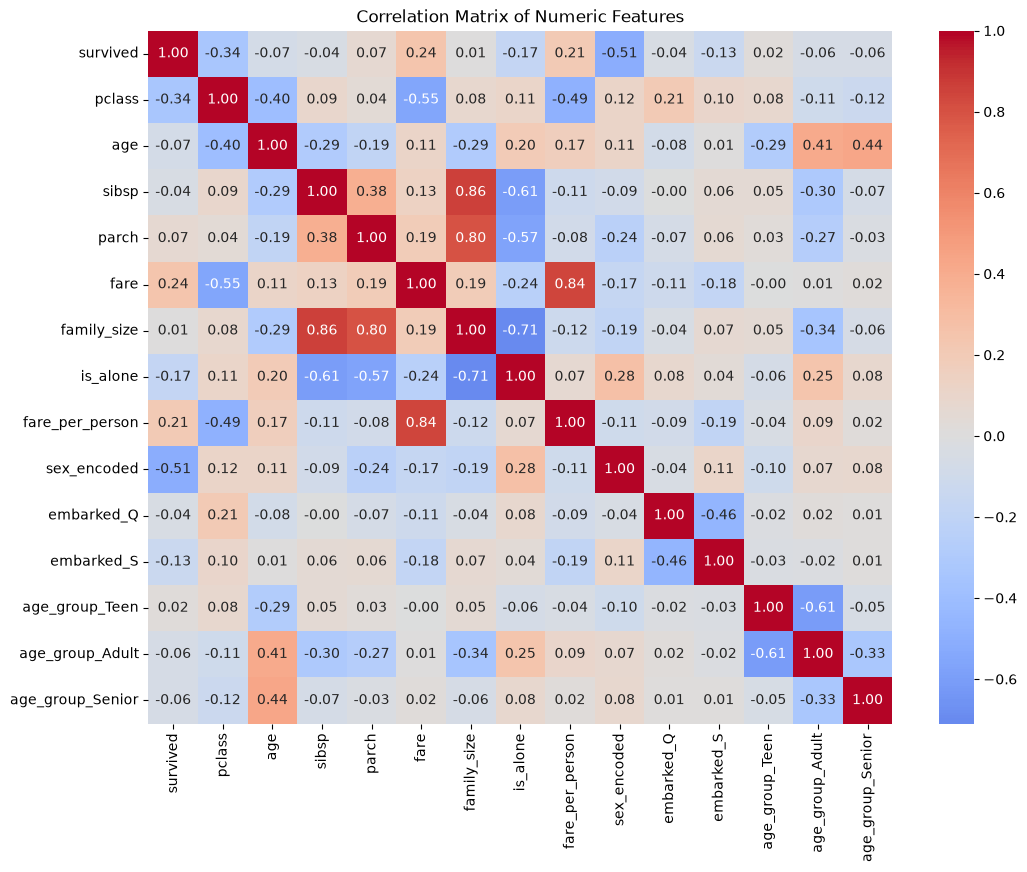

In [299]:
# 3) Heatmap
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix of Numeric Features')
plt.show()

### Answer Q6.4

`sex_encoded` has the most negative correlation with survival (-0.51). Male is 1 and female is 0, so men were much less likely to survive than women.

`fare` has the most positive correlation (0.24), so passengers who paid more survived more often. The link is weak, and part of it probably comes from class: `fare` and `pclass` are correlated at -0.55, and `pclass` itself has -0.34 with survival. This is only correlation, so it does not show that paying more saved anyone.

---
<h2 style="text-align:center; color:blue;">Part 4: Visualisation</h2>

---

## Q7. Survival Heatmap by Pclass × Embarked

1. Create a pivot table with `pclass` as rows, `embarked` as columns, and `survived` mean as values.
2. Plot it as a heatmap (`annot=True`, `fmt='.0%'`, `cmap='RdYlGn'`). Title: `'Survival Rate by Class & Embarkation Port'`.
3. In a Markdown cell, interpret the heatmap, which combination of class and port gave the best and worst survival chances?

In [300]:
# 1) Pivot table
class_port_pivot = df_clean.pivot_table(index='pclass', columns='embarked', values='survived', aggfunc='mean')
class_port_pivot

embarked,C,Q,S
pclass,,,
1,0.707317,0.500000,0.60000
2,0.529412,0.666667,0.50000
3,0.425926,0.320755,0.21843


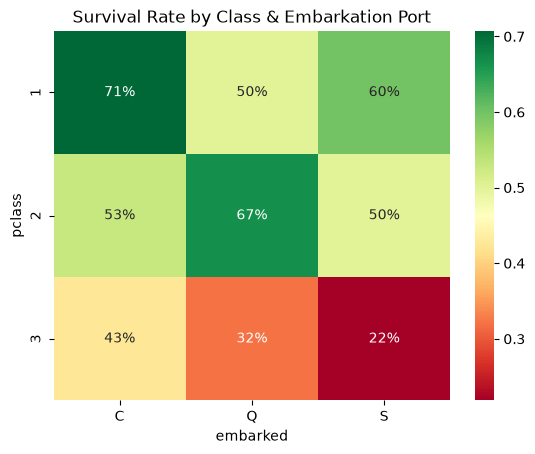

In [301]:
# 2) Heatmap
sns.heatmap(class_port_pivot, annot=True, fmt='.0%', cmap='RdYlGn')
plt.title('Survival Rate by Class & Embarkation Port')
plt.show()

### Answer Q7.3

1st class passengers from Cherbourg (`C`) had the best chance, about 71%. 3rd class passengers from Southampton (`S`) had the worst, about 22%. At every port 3rd class has the lowest rate, so class clearly matters. The best port is not the same for every class, though, because `Q` is the best one for 2nd class.

---

## Q8. FacetGrid: Age Distribution by Survival & Sex

1. Use `sns.FacetGrid` with `col='survived'`, `row='sex'`, and `height=3` to create a grid of histograms of `age`. Use `map(sns.histplot, 'age', bins=20, kde=True)`.
2. Set meaningful column titles and add a main title.
3. In a Markdown cell, describe one pattern you see comparing surviving vs non-surviving passengers across both sexes.

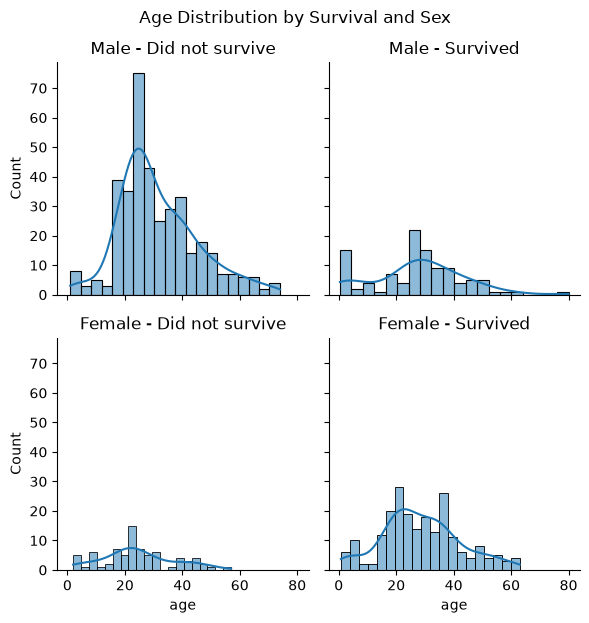

In [302]:
g = sns.FacetGrid(df_clean, col='survived', row='sex', height=3)
g.map(sns.histplot, 'age', bins=20, kde=True)
for (sex, survived), ax in g.axes_dict.items():
    ax.set_title(f"{sex.capitalize()} - {'Survived' if survived == 1 else 'Did not survive'}")
g.fig.suptitle('Age Distribution by Survival and Sex', y=1.03)
plt.show()

### Answer Q8.3

Sex changes the picture more than age does. In the male row, non survivors far outnumber survivors, mostly between ages 20 and 40. In the female row it is the opposite, and at most ages more women survived than died. Very young boys also form a small peak among the male survivors.

---

## Q9. Family Size vs Survival: Bar Chart with Error Bars

1. Using `df_clean`, compute the mean survival rate per `family_size` value.
2. Plot a bar chart (`sns.barplot`) with `x='family_size'`, `y='survived'`, `data=df_clean`, `ci=95` (confidence interval). Title: `'Survival Rate by Family Size'`.
3. In a Markdown cell, interpret the relationship, is travelling alone beneficial?

family_size
1     0.34
2     0.55
3     0.57
4     0.71
5     0.23
6     0.14
7     0.33
8     0.00
11    0.00
Name: survived, dtype: float64


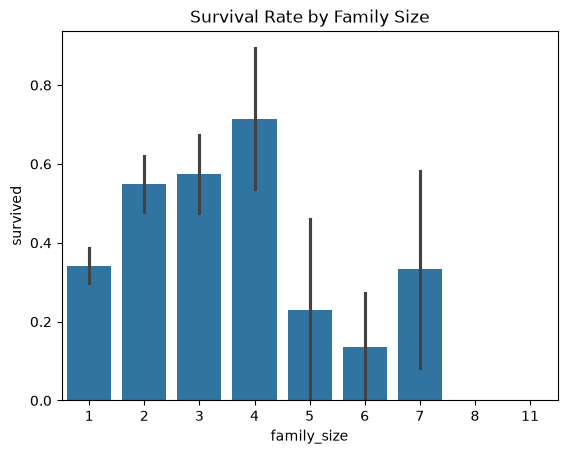

In [303]:
print(df_clean.groupby('family_size')['survived'].mean().round(2))

sns.barplot(x='family_size', y='survived', data=df_clean, errorbar=('ci', 95))
plt.title('Survival Rate by Family Size')
plt.show()

### Answer Q9.3

No, travelling alone was not better than travelling with a small family. Passengers alone have a survival rate of 0.34, while families of 2, 3, and 4 have 0.55, 0.57, and 0.71. A bigger family does not always help, though. Sizes 5 and 6 drop to 0.23 and 0.14, and sizes 8 and 11 have 0, so passengers alone still did better than these large families. The error bars for sizes 5 to 7 are wide, so I would not read too much into those rates.

---
<h2 style="text-align:center; color:blue;">Part 5: Machine Learning: Classification</h2>

---

## Q10. Prepare the Feature Matrix

1. Define the feature set `X` using the following columns:
   `['pclass', 'sex_encoded', 'age', 'sibsp', 'parch', 'fare', 'family_size', 'is_alone', 'fare_per_person']`
2. Define the target `y` as `survived`.
3. Split into train/test sets with `test_size=0.2` and `random_state=42`. Print the sizes.
4. Scale the features using `StandardScaler`. Fit on train, transform both train and test (explain why in a Markdown cell).

In [304]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

features = ['pclass', 'sex_encoded', 'age', 'sibsp', 'parch', 'fare', 'family_size', 'is_alone', 'fare_per_person']
X = df_clean[features]
y = df_clean['survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train size: {X_train.shape}\nTest size: {X_test.shape}")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Train size: (618, 9)
Test size: (155, 9)


### Answer Q10.4

If the scaler is fitted on all the data, its mean and standard deviation include the test set, and information from the test set leaks into training. So I fit it only on the train set. Then I use the same train values to transform the test set, which puts both sets on the same scale and keeps the test set unseen.

---

## Q11. Logistic Regression Classifier

1. Train a `LogisticRegression(max_iter=1000, random_state=42)` on the scaled training data.
2. Predict on the scaled test set.
3. Print the accuracy, the confusion matrix, and the full classification report.
4. Plot the confusion matrix as a heatmap using `sns.heatmap`.
5. In a Markdown cell, explain what precision, recall, and F1-score mean in the context of predicting survival.

In [305]:
# 1) Train
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [306]:
# 2) Predict
y_pred_lr = log_reg.predict(X_test_scaled)

In [307]:
# 3) Metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

cm = confusion_matrix(y_test, y_pred_lr)
print(f"Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Confusion matrix:\n{cm}")
print(classification_report(y_test, y_pred_lr))

Accuracy: 0.8000
Confusion matrix:
[[77  8]
 [23 47]]
              precision    recall  f1-score   support

           0       0.77      0.91      0.83        85
           1       0.85      0.67      0.75        70

    accuracy                           0.80       155
   macro avg       0.81      0.79      0.79       155
weighted avg       0.81      0.80      0.80       155



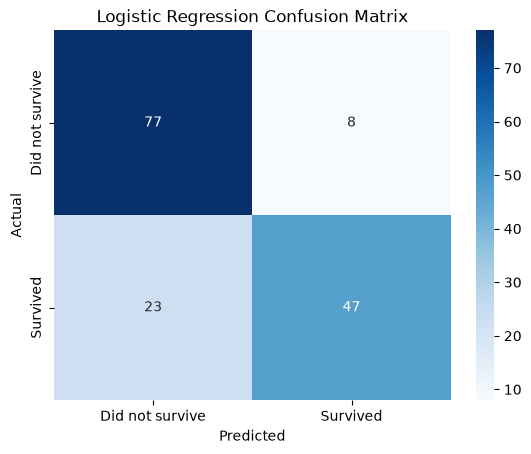

In [308]:
# 4) Confusion matrix heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Did not survive', 'Survived'], yticklabels=['Did not survive', 'Survived'])
plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### Answer Q11.5

These numbers are for the `Survived` class.

Precision is 0.85. Out of the passengers the model predicted as survivors, 85% really survived.

Recall is 0.67. The model found 47 of the 70 real survivors and missed the other 23.

F1 score is 0.75. It is the harmonic mean of precision and recall, so it is high only when both of them are high.

So when this model says someone survived it is usually right, but it misses about one third of the survivors.

---

## Q12. Decision Tree Classifier & Comparison

1. Train a `DecisionTreeClassifier(max_depth=5, random_state=42)` on the unscaled training data (decision trees don't require scaling, explain why in a Markdown cell).
2. Evaluate it on the test set and print accuracy and classification report.
3. Use `cross_val_score` with `cv=5` to compute the 5-fold cross-validated accuracy for both Logistic Regression and the Decision Tree (use scaled data for LR, unscaled for DT).
4. Create a side-by-side bar chart comparing the CV accuracy distributions of both models.
5. In a Markdown cell, state which model you would recommend and why.

In [309]:
# 1 & 2) Decision Tree
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(max_depth=5, random_state=42)
tree.fit(X_train, y_train)
y_pred_tree = tree.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred_tree):.4f}")
print(classification_report(y_test, y_pred_tree))

Accuracy: 0.7871
              precision    recall  f1-score   support

           0       0.77      0.88      0.82        85
           1       0.82      0.67      0.74        70

    accuracy                           0.79       155
   macro avg       0.79      0.78      0.78       155
weighted avg       0.79      0.79      0.78       155



In [310]:
# 3) 5-fold cross-validation
from sklearn.model_selection import cross_val_score

lr_cv = cross_val_score(log_reg, X_train_scaled, y_train, cv=5)
tree_cv = cross_val_score(tree, X_train, y_train, cv=5)

print(f"Logistic Regression: {lr_cv.round(4)}, mean = {lr_cv.mean():.4f}, std = {lr_cv.std():.4f}")
print(f"Decision Tree: {tree_cv.round(4)}, mean = {tree_cv.mean():.4f}, std = {tree_cv.std():.4f}")

Logistic Regression: [0.7742 0.7903 0.8065 0.813  0.7154], mean = 0.7799, std = 0.0349
Decision Tree: [0.8145 0.7742 0.8387 0.8374 0.7805], mean = 0.8091, std = 0.0274


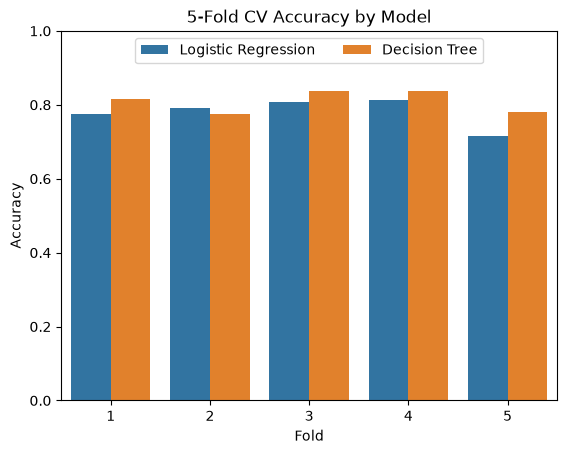

In [311]:
# 4) Side-by-side CV accuracy comparison
cv_results = pd.DataFrame({
    'Fold': list(range(1, 6)) * 2,
    'Accuracy': list(lr_cv) + list(tree_cv),
    'Model': ['Logistic Regression'] * 5 + ['Decision Tree'] * 5,
})

sns.barplot(data=cv_results, x='Fold', y='Accuracy', hue='Model')
plt.title('5-Fold CV Accuracy by Model')
plt.ylim(0, 1)
plt.legend(loc='upper center', ncol=2)
plt.show()

### Answer Q12

A decision tree looks at one feature at a time and splits it at a threshold. Scaling does not change the order of the values inside a feature, so the tree can make the same splits with or without it. Logistic Regression is different because it adds the features together with weights, so their scale matters.

### Answer Q12.5

I would pick the Decision Tree. Its mean CV accuracy is higher (0.809 vs 0.780), it wins in 4 of the 5 folds, and its scores change a bit less between folds (std 0.027 vs 0.035). It is also easier to explain.

Logistic Regression did better on the test set (0.800 vs 0.787), but that is only 2 passengers out of 155, so I trust CV more. The gap is small either way, so this is not a strong win.

---

## Q13. Feature Importance

1. Extract the Decision Tree feature importances and create a horizontal bar chart sorted from most to least important. Label each bar with its importance value.
2. Extract the Logistic Regression coefficients and plot them similarly (positive = increases survival probability, negative = decreases).
3. In a Markdown cell, identify the top 2 most important features in each model and discuss whether they agree.

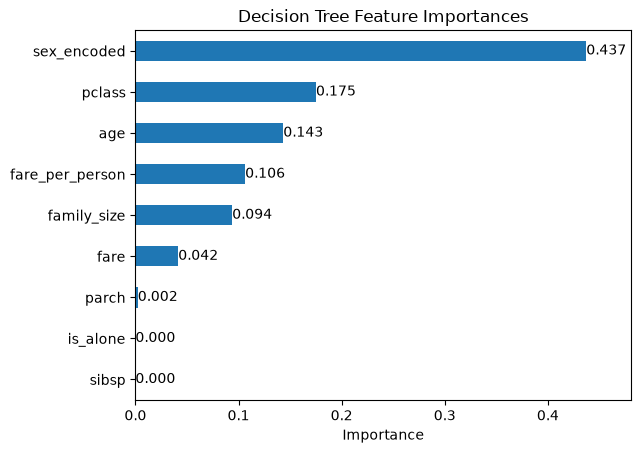

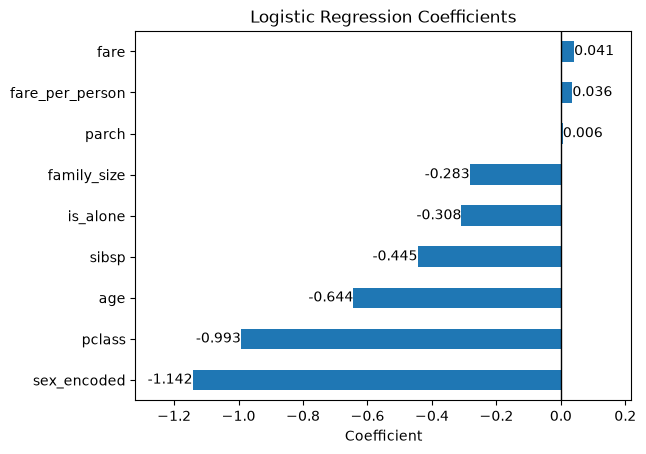

In [312]:
#1) Decision Tree feature importances 
tree_importances = pd.Series(tree.feature_importances_, index=features).sort_values()
ax = tree_importances.plot(kind='barh')
ax.bar_label(ax.containers[0], fmt='%.3f')
ax.set_title('Decision Tree Feature Importances')
ax.set_xlabel('Importance')
ax.margins(x=0.1)
plt.show()

#2) Logistic Regression coefficients 
lr_coefficients = pd.Series(log_reg.coef_[0], index=features).sort_values()
ax = lr_coefficients.plot(kind='barh')
ax.bar_label(ax.containers[0], fmt='%.3f')
ax.axvline(0, color='black', linewidth=1)
ax.set_title('Logistic Regression Coefficients')
ax.set_xlabel('Coefficient')
ax.margins(x=0.15)
plt.show()

### Answer Q13.3

In the Decision Tree, the top 2 features are `sex_encoded` (0.437) and `pclass` (0.175). In Logistic Regression, the top 2 by absolute value are the same: `sex_encoded` (-1.142) and `pclass` (-0.993). So the models agree. Both coefficients are negative, which means being male or being in a lower class lowers the predicted chance of survival.

They disagree more on the smaller features. `sibsp` has 0 importance in the tree but -0.445 in Logistic Regression. `sibsp`, `parch`, and `family_size` carry almost the same information, so each model can divide it between them differently. Importance and coefficients are also different kinds of numbers, so I compare only their order and not their size.

---
<h2 style="text-align:center; color:blue;">Part 6: Tips Dataset: Regression &amp; Insight</h2>

---

## Q14. Tips Exploration

Using the `tips` dataset:

1. Create a new column `tip_pct` = `tip / total_bill * 100` (tip percentage), rounded to 2 decimal places.
2. Use `.groupby` to compute the mean, median, and standard deviation of `tip_pct` grouped by both `sex` and `smoker`. Display all 4 combinations.
3. Plot a violin plot (`sns.violinplot`) of `tip_pct` grouped by `day`, split by `sex` using `hue='sex'`. Title: `'Tip % Distribution by Day and Sex'`.
4. In a Markdown cell, answer: which group (sex × smoker combination) tips the most generously as a percentage?

In [313]:
# 1) Tip percentage
tips['tip_pct'] = (tips['tip'] / tips['total_bill'] * 100).round(2)

In [314]:
# 2) GroupBy sex + smoker
tips.groupby(['sex', 'smoker'], observed=True)['tip_pct'].agg(['mean', 'median', 'std']).round(2)

mean  median   std
sex    smoker                     
Male   Yes     15.28   14.10  9.06
       No      16.07   15.76  4.18
Female Yes     18.21   17.39  7.16
       No      15.69   14.97  3.64

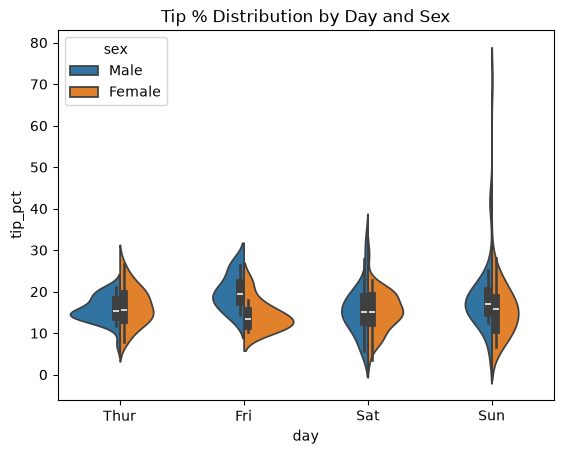

In [315]:
# 3) Violin plot
sns.violinplot(data=tips, x='day', y='tip_pct', hue='sex', split=True)
plt.title('Tip % Distribution by Day and Sex')
plt.show()

### Answer Q14.4

Female smokers tip the most, with a mean of 18.21% and a median of 17.39%, both the highest of the four groups. Their tips also vary more than those of female non smokers (std 7.16 vs 3.64).

---

## Q15. Multiple Linear Regression on Tips

Build a multiple linear regression model to predict `tip` using more than one feature:

1. Encode `sex`, `smoker`, `day`, and `time` using `pd.get_dummies(drop_first=True)`. Concatenate with `total_bill` and `size`.
2. Define `X` and `y = tips['tip']`. Split 80/20 with `random_state=0`.
3. Train a `LinearRegression` model. Print the R² score and RMSE for both train and test sets.
4. Create a residual plot: scatter `y_pred` (x-axis) vs `residuals = y_test - y_pred` (y-axis). Add a horizontal line at y=0.
5. In a Markdown cell, interpret the R² and comment on whether the residual plot suggests any issues.

In [316]:
# 1) Encode categoricals
encoded = pd.get_dummies(tips[['sex', 'smoker', 'day', 'time']], drop_first=True, dtype=int)
X = pd.concat([tips[['total_bill', 'size']], encoded], axis=1)

In [317]:
# 2) Split
y = tips['tip']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [318]:
# 3) Train & evaluate
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, root_mean_squared_error

lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
y_pred_train = lin_reg.predict(X_train)
y_pred = lin_reg.predict(X_test)

print(f"Train R2: {r2_score(y_train, y_pred_train):.4f}, RMSE: {root_mean_squared_error(y_train, y_pred_train):.4f}")
print(f"Test R2: {r2_score(y_test, y_pred):.4f}, RMSE: {root_mean_squared_error(y_test, y_pred):.4f}")

Train R2: 0.4345, RMSE: 1.0313
Test R2: 0.5545, RMSE: 0.9455


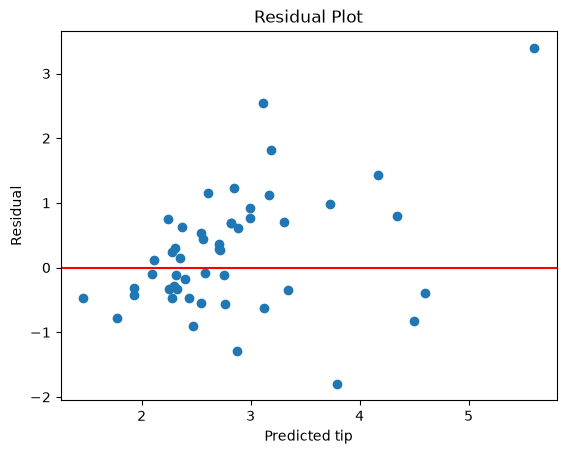

In [319]:
# 4) Residual plot
residuals = y_test - y_pred

plt.scatter(y_pred, residuals)
plt.axhline(0, color='red')
plt.title('Residual Plot')
plt.xlabel('Predicted tip')
plt.ylabel('Residual')
plt.show()

### Answer Q15.5

The test R² is 0.55, so the model explains about 55% of the variation in tips and leaves a lot unexplained. The train R² is 0.43. A test score above the train score is unusual, but the test set has only 49 rows, so this could just be luck of the split. I do not see overfitting here. The test RMSE is 0.95, so a typical prediction is off by about $0.95.

The residual plot does show some problems. The points spread out more as the predicted tip grows, which suggests heteroscedasticity. There are also a few large errors, like the point with a predicted tip near 5.6 and a residual near 3.4. I would trust this model less for large tips.